# 05 — Comparación con literatura (13 fuentes, 3 grupos)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 5 — Comparación con literatura

Objetivos:
1. Cargar la tabla comparativa de literatura verificada (13 fuentes: 4 Grupo A externas + este estudio, 4 Grupo B, 4 Grupo C)
2. Ubicar el resultado propio dentro del contexto de la literatura
3. Generar un gráfico de puntos comparando elasticidades (Grupos A y B con coeficientes numéricos)
4. Guardar salidas en reports/notebook_outputs/ y figura en reports/figuras/

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)

In [2]:
from pathlib import Path

REPORTS_DIR = Path('../reports')
NOTEBOOK_OUTPUTS_DIR = REPORTS_DIR / 'notebook_outputs'
FIGURES_DIR = NOTEBOOK_OUTPUTS_DIR  # figuras de trabajo; las del informe están en Informe/figuras
NOTEBOOK_OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def guardar_texto(nombre_archivo: str, contenido: str) -> Path:
    ruta = NOTEBOOK_OUTPUTS_DIR / nombre_archivo
    ruta.write_text(str(contenido), encoding='utf-8')
    return ruta

def guardar_tabla(nombre_base: str, tabla: pd.DataFrame) -> tuple[Path, Path]:
    ruta_txt = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.txt'
    ruta_csv = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.csv'
    tabla.to_csv(ruta_csv, index=False)
    ruta_txt.write_text(tabla.to_string(index=False), encoding='utf-8')
    return ruta_txt, ruta_csv

## 1. Cargar tabla comparativa completa (12 fuentes)

In [3]:
tabla = pd.read_csv('../data/processed/tabla_comparativa_literatura.csv')
ruta_tabla, ruta_tabla_csv = guardar_tabla('05_comparacion_literatura_tabla_completa', tabla)
print(f'Tabla completa guardada en {ruta_tabla_csv} y {ruta_tabla}')
print(f'Total fuentes: {len(tabla)}')
print(tabla[['grupo', 'autor', 'anio', 'elasticidad']].to_string(index=False))

Tabla completa guardada en ../reports/notebook_outputs/05_comparacion_literatura_tabla_completa.csv y ../reports/notebook_outputs/05_comparacion_literatura_tabla_completa.txt
Total fuentes: 13
grupo                         autor  anio  elasticidad
    A    Andreyeva, Long & Brownell  2010       -0.810
    A Damayanti, Nuryakin & Muchtar  2023       -0.920
    A               Bumagat & Ibana  2025       -0.420
    A                     Li & Wang  2025          NaN
    A                  Este estudio  2026       -0.759
    B           Christensen & Osman  2021       -0.840
    B     Christensen, Nino & Osman  2023          NaN
    B              Zhang & Demirkan  2021       -0.870
    B      Sriwongphanawes & Fukuda  2024       -0.150
    C                      Statista  2024          NaN
    C    Kahneman, Knetsch & Thaler  1991          NaN
    C                      Davidson  1994          NaN
    C                  Long & Ervin  2000          NaN


## 2. Resumen por grupos

In [4]:
print('=== GRUPO A: Directamente comparable (comida/delivery) ===')
grupo_a = tabla[tabla['grupo'] == 'A']
print(grupo_a[['autor', 'anio', 'elasticidad', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo A: {len(grupo_a)} fuentes (4 externas + este estudio)')

print('\n=== GRUPO B: Contextual (on-demand/e-commerce) ===')
grupo_b = tabla[tabla['grupo'] == 'B']
print(grupo_b[['autor', 'anio', 'elasticidad', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo B: {len(grupo_b)} fuentes')

print('\n=== GRUPO C: Soporte metodológico/mercado ===')
grupo_c = tabla[tabla['grupo'] == 'C']
print(grupo_c[['autor', 'anio', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo C: {len(grupo_c)} fuentes')

ruta_grupos, ruta_grupos_csv = guardar_tabla('05_comparacion_literatura_resumen_grupos', 
    tabla.groupby('grupo').agg(
        n_fuentes=('autor', 'count'),
        elasticidad_promedio=('elasticidad', 'mean')
    ).reset_index())
print(f'\nResumen grupos guardado en {ruta_grupos_csv} y {ruta_grupos}')

=== GRUPO A: Directamente comparable (comida/delivery) ===
                        autor  anio  elasticidad                                         metodo
   Andreyeva, Long & Brownell  2010       -0.810                           Revision sistematica
Damayanti, Nuryakin & Muchtar  2023       -0.920                                        LA/AIDS
              Bumagat & Ibana  2025       -0.420                        Comparativo cualitativo
                    Li & Wang  2025          NaN Revision literatura / Identificacion de brecha
                 Este estudio  2026       -0.759                      OLS log-log con controles

Total Grupo A: 5 fuentes (4 externas + este estudio)

=== GRUPO B: Contextual (on-demand/e-commerce) ===
                    autor  anio  elasticidad                      metodo
      Christensen & Osman  2021        -0.84         Experimental (2SLS)
Christensen, Nino & Osman  2023          NaN         Experimental (2SLS)
         Zhang & Demirkan  2021        -

## 3. Filtrar solo las entradas con coeficiente cuantificado (Grupos A y B)

In [5]:
# Solo Grupos A y B tienen elasticidades numéricas para el gráfico
tabla_cuantificada = tabla[tabla['grupo'].isin(['A', 'B'])].dropna(subset=['elasticidad']).copy()
tabla_cuantificada['etiqueta'] = tabla_cuantificada['autor'] + ' (' + tabla_cuantificada['anio'].astype(str) + ')'
ruta_cuantificada, ruta_cuantificada_csv = guardar_tabla('05_comparacion_literatura_tabla_cuantificada', 
    tabla_cuantificada[['grupo', 'etiqueta', 'elasticidad', 'contexto']])
print(f'Tabla cuantificada guardada en {ruta_cuantificada_csv} y {ruta_cuantificada}')
print(tabla_cuantificada[['grupo', 'etiqueta', 'elasticidad', 'contexto']].to_string(index=False))

Tabla cuantificada guardada en ../reports/notebook_outputs/05_comparacion_literatura_tabla_cuantificada.csv y ../reports/notebook_outputs/05_comparacion_literatura_tabla_cuantificada.txt
grupo                             etiqueta  elasticidad                                                     contexto
    A    Andreyeva, Long & Brownell (2010)       -0.810               Meta-analisis, 160 estudios, mayormente EE.UU.
    A Damayanti, Nuryakin & Muchtar (2023)       -0.920     Indonesia, Susenas 2011-2013, panel 24376 obs. hogar-ano
    A               Bumagat & Ibana (2025)       -0.420                          Metro Manila, horas pico vs no pico
    A                  Este estudio (2026)       -0.759 Dataset Kaggle/Genpact, 456548 observaciones transaccionales
    B           Christensen & Osman (2021)       -0.840                  Experimento aleatorizado con Uber, El Cairo
    B              Zhang & Demirkan (2021)       -0.870                              CPG online vs. offline, EE

## 4. Gráfico comparativo de elasticidades (Grupos A y B)

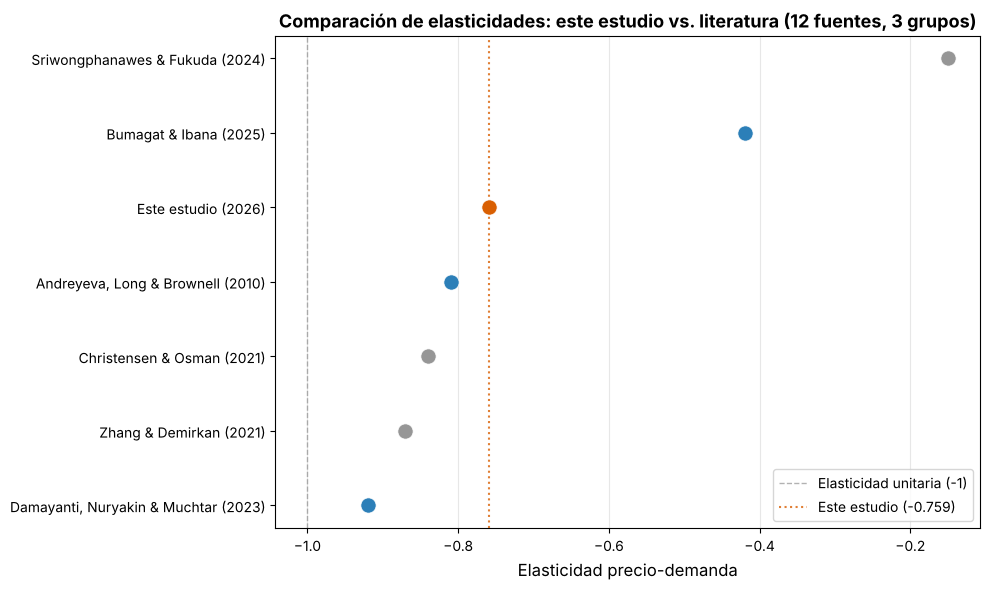

Gráfico guardado en ../reports/notebook_outputs/comparacion_elasticidad_literatura_notebook.png


In [6]:
colores = {'A': '#2c7fb8', 'B': '#969696'}
tabla_ordenada = tabla_cuantificada.sort_values('elasticidad')

fig, ax = plt.subplots(figsize=(10, 6))

for _, fila in tabla_ordenada.iterrows():
    color = '#d95f02' if 'este estudio' in fila['autor'].lower() else colores[fila['grupo']]
    ax.scatter(fila['elasticidad'], fila['etiqueta'], s=120, color=color, zorder=3, edgecolors='white', linewidth=0.5)

# Línea de elasticidad unitaria
ax.axvline(-1, color='gray', linestyle='--', linewidth=1, alpha=0.6, label='Elasticidad unitaria (-1)')

# Línea del resultado propio
ax.axvline(-0.759, color='#d95f02', linestyle=':', linewidth=1.5, alpha=0.8, label='Este estudio (-0.759)')

ax.set_xlabel('Elasticidad precio-demanda', fontsize=12)
ax.set_title('Comparación de elasticidades: este estudio vs. literatura (12 fuentes, 3 grupos)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
ruta_figura = NOTEBOOK_OUTPUTS_DIR / 'comparacion_elasticidad_literatura_notebook.png'
plt.savefig(ruta_figura, dpi=150, bbox_inches='tight')
plt.show()
print(f'Gráfico guardado en {ruta_figura}')

**Leyenda:** azul = Grupo A (comida fuera del hogar/delivery, directamente comparable); gris = Grupo B (servicios on-demand/e-commerce, contextual); naranja = resultado propio de este estudio.

## 5. Discusión comparativa (resumen para el informe)

In [7]:
print('La discusión comparativa completa está en el informe (sección "Comparación con la Literatura").')
print(tabla[['grupo', 'autor', 'anio', 'elasticidad', 'nota']].to_string(index=False))

La discusión comparativa completa está en el informe (sección "Comparación con la Literatura").
grupo                         autor  anio  elasticidad                                                                                                                                                                                                                     nota
    A    Andreyeva, Long & Brownell  2010       -0.810                                                                                                           Valor puntual para comida fuera del hogar (FAFH) en el meta-analisis; rango general 0.27-0.81 segun categoria.
    A Damayanti, Nuryakin & Muchtar  2023       -0.920                                                                                                                                                             Elasticidad propia agregada de FAFH (comida fuera del hogar)
    A               Bumagat & Ibana  2025       -0.420                                  

## 6. Archivos generados

In [8]:
import os
print('=== ARCHIVOS EN reports/notebook_outputs/ ===')
for f in sorted(NOTEBOOK_OUTPUTS_DIR.glob('05_*')):
    print(f'  {f.name} ({f.stat().st_size:,} bytes)')

print('\n=== ARCHIVOS EN reports/figuras/ ===')
for f in sorted(FIGURES_DIR.glob('*literatura*')):
    print(f'  {f.name} ({f.stat().st_size:,} bytes)')

=== ARCHIVOS EN reports/notebook_outputs/ ===
  05_comparacion_literatura_resumen_grupos.csv (65 bytes)
  05_comparacion_literatura_resumen_grupos.txt (155 bytes)
  05_comparacion_literatura_tabla_completa.csv (3,238 bytes)
  05_comparacion_literatura_tabla_completa.txt (6,342 bytes)
  05_comparacion_literatura_tabla_cuantificada.csv (612 bytes)
  05_comparacion_literatura_tabla_cuantificada.txt (935 bytes)

=== ARCHIVOS EN reports/figuras/ ===
  05_comparacion_literatura_resumen_grupos.csv (65 bytes)
  05_comparacion_literatura_resumen_grupos.txt (155 bytes)
  05_comparacion_literatura_tabla_completa.csv (3,238 bytes)
  05_comparacion_literatura_tabla_completa.txt (6,342 bytes)
  05_comparacion_literatura_tabla_cuantificada.csv (612 bytes)
  05_comparacion_literatura_tabla_cuantificada.txt (935 bytes)
  comparacion_elasticidad_literatura_notebook.png (113,046 bytes)


## Próximos pasos (Fase 7 — Informe final + empaquetado)
- Informe final en LaTeX (`apa7.cls`, una columna) integrando todas las fases
- README completo del repositorio
- CITATION.cff
- Verificación de reproducibilidad end-to-end
- Release GitHub → Zenodo con DOI